# Gear dynamics 03: time-varying mesh stiffness and transmission error

In notebook 02 the mesh was a constant spring, so a gear pair running at constant torque did
nothing interesting. Real pairs whine. The main reason is that the **number of tooth pairs in
contact alternates** (notebook 01, $\varepsilon_\alpha = 1.675$), so the stiffness alternates too:

$$k = k(s),\qquad s = \frac{z_1\theta_1}{2\pi}\ \ \text{(mesh position in base pitches)} .$$

Under load this produces a periodic **transmission error** at the tooth-mesh frequency
$f_z = z_1 n_1/60$ and its harmonics. That is the internal excitation of every gearbox.

**Contents:** the stiffness model · static transmission error · the 1-DOF
dynamic-transmission-error equation (checked against the 2-DOF model) · time histories ·
speed sweep and dynamic factor · Campbell diagram · parametric stability (Floquet).
**Experiments:** tip relief · high contact ratio · manufacturing error versus load.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import geardyn as gd

gd.style()
gp = gd.GearPair()
T1 = 40.0
Fm = T1 / gp.rb1                        # mean (static) mesh force
print(gp.summary())
print(f"mean mesh force Fm = {Fm:.0f} N; mesh frequency = z1*n1/60 = {gp.z1/60:.2f} Hz per rpm")

z1 / z2                                 24 / 48  -
ratio i = z2/z1                           2.000  -
module                                     2.50  mm
pressure angle                             20.0  deg
pitch radii r1 / r2               30.00 / 60.00  mm
base radii rb1 / rb2              28.19 / 56.38  mm
centre distance a                         90.00  mm
base pitch pb                             7.380  mm
contact ratio eps_alpha                   1.675  -
J1 / J2                   1.498e-04 / 2.397e-03  kg m^2
m1 / m2                           0.333 / 1.332  kg
equivalent mass m_eq                     0.1508  kg
mesh stiffness k (mean)                   316.3  N/um
mesh damping c                            690.6  N s/m
mesh natural frequency                     7288  Hz
backlash j_n                                  0  um
mean mesh force Fm = 1419 N; mesh frequency = z1*n1/60 = 0.40 Hz per rpm


## 1  The stiffness model

Per mesh cycle the contact goes from double contact (two pairs, for a fraction
$\varepsilon_\alpha - 1$ of the cycle) to single contact and back. `geardyn` models $k(s)$ as a
smoothed rectangular wave:

* single-pair stiffness $k_s$, double-contact stiffness $k_d = r\,k_s$ with $r =$ `tv_ratio`
  $= 1.6$. Two pairs are less than twice as stiff, because they share the gear body;
* $k_s$ is scaled so the **mean equals** the ISO value $k = c_{\gamma\alpha} b$ of notebook 02;
* the transitions have a width of `tv_smooth` $= 0.03$ base pitches, standing in for tip and root
  relief and for the fact that a pair takes up load gradually.

Real single-pair stiffness also varies along the path (parabolic, highest near the pitch
point). FE or Weber/Banaschek and Kuang-Yang formulae give it. The rectangular wave catches
the dominant effect and keeps the physics visible.

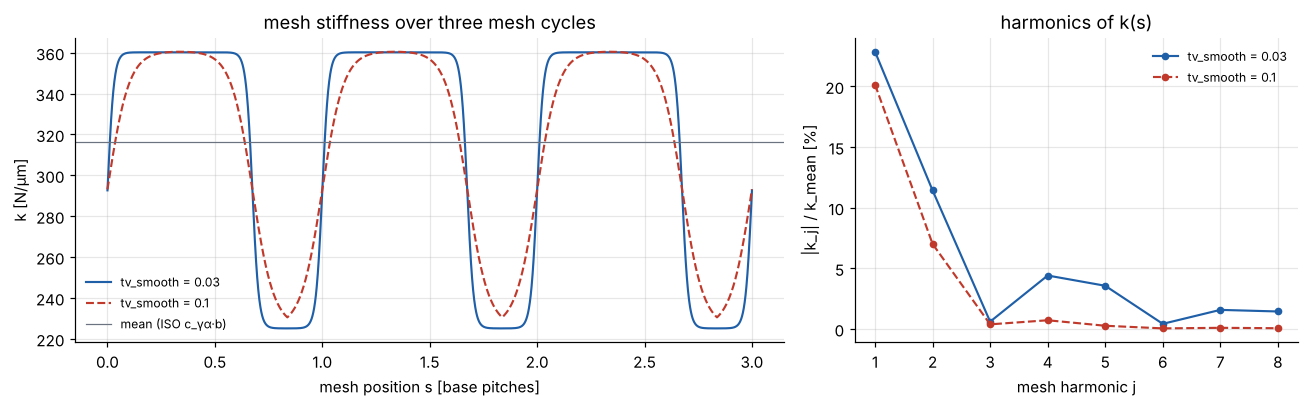

In [2]:
s = np.linspace(0, 3, 3001)
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw=dict(width_ratios=[1.6, 1]))
for sw, ls in [(0.03, "-"), (0.10, "--")]:
    g = gp.with_(tv_smooth=sw)
    ax[0].plot(s, g.k_of_s(s) / 1e6, ls, label=f"tv_smooth = {sw}")
ax[0].axhline(gp.k_mesh / 1e6, color=gd.C["grey"], lw=0.8, label="mean (ISO c_γα·b)")
ax[0].set_xlabel("mesh position s [base pitches]"); ax[0].set_ylabel("k [N/µm]")
ax[0].legend(fontsize=8); ax[0].set_title("mesh stiffness over three mesh cycles")
# harmonic content
N = 4096; sh = np.arange(N) / N
for sw, ls in [(0.03, "-"), (0.10, "--")]:
    kk = gp.with_(tv_smooth=sw).k_of_s(sh)
    A = 2 * np.abs(np.fft.rfft(kk)) / N / gp.k_mesh
    ax[1].plot(np.arange(1, 9), A[1:9] * 100, ls + "o", ms=4, label=f"tv_smooth = {sw}")
ax[1].set_xlabel("mesh harmonic j"); ax[1].set_ylabel("|k_j| / k_mean [%]")
ax[1].set_title("harmonics of k(s)"); ax[1].legend(fontsize=8)
plt.tight_layout()

## 2  Static transmission error

Run the pair very slowly at constant torque. The teeth deflect by
$\delta_s(s) = F_m / k(s)$. This **loaded static transmission error (STE)** is what a
transmission-error test rig measures at crawl speed, and it is the standard quality metric
for gear noise (together with the manufacturing error of section 8).

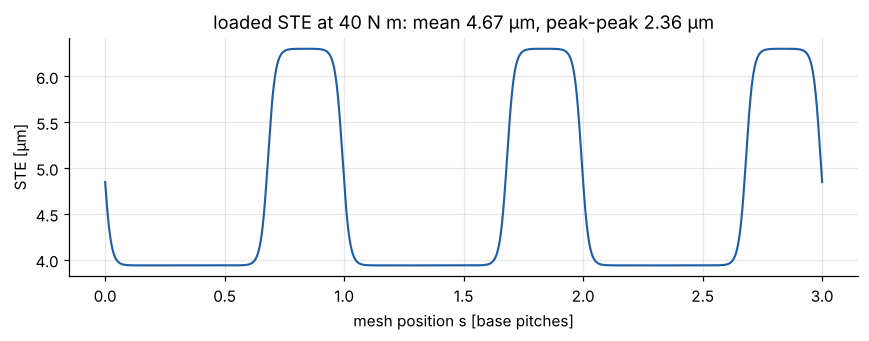

In [3]:
ste = Fm / gp.k_of_s(s)
fig, ax = plt.subplots(figsize=(8, 3.2))
ax.plot(s, ste * 1e6)
ax.set_xlabel("mesh position s [base pitches]"); ax.set_ylabel("STE [µm]")
ax.set_title(f"loaded STE at {T1:.0f} N m: mean {ste.mean()*1e6:.2f} µm, peak-peak {np.ptp(ste)*1e6:.2f} µm")
plt.tight_layout()

## 3  The 1-DOF dynamic-transmission-error equation

From notebook 02, with $T_2 = i\,T_1$ (constant mean speed) and stiffness now depending on the
mesh position:

$$m_{eq}\,\ddot\delta + c\,\dot\delta + k(f_z t)\,\delta = F_m$$

This is a **linear equation with a periodic coefficient** (Hill/Mathieu type) and a constant
right-hand side. The steady response is periodic at $f_z$ and has every harmonic of it. Two
small approximations: the mesh position is taken from the mean speed ($s = f_z t$), and the
torque ripple $-\tfrac12 k'\delta^2$ that `Model` includes is dropped. The comparison
below shows both are negligible.

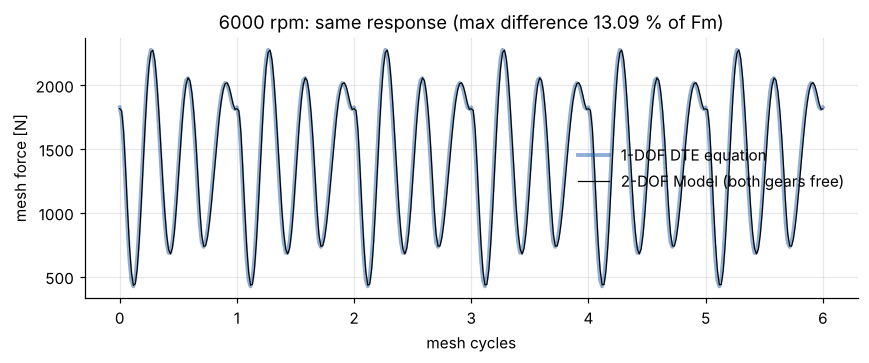

In [4]:
n_chk = 6000
r1 = gd.simulate_dte(gp, n_chk, Fm, cycles=60, keep=6)
m = gd.torsional_pair(gp, contact="linear", stiffness="tv")
m.add_load("th1", lambda t, q, v: T1)
m.add_load("th2", lambda t, q, v: -gp.i * T1)
W = n_chk * 2 * np.pi / 60
Q = np.zeros(2); Q[0] = T1; Q[1] = -gp.i * T1
q0 = m.static(Q)
rM = m.simulate(r1["t"][-1], q0=q0, v0=[W, W / gp.i], t_eval=r1["t"], max_step=1 / gp.f_mesh(n_chk) / 60)
F_M = rM.mesh[0]["F"]
fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(r1["s"] - r1["s"][0], r1["F"], lw=2.5, alpha=0.5, label="1-DOF DTE equation")
ax.plot(r1["s"] - r1["s"][0], F_M, "k", lw=0.8, label="2-DOF Model (both gears free)")
ax.set_xlabel("mesh cycles"); ax.set_ylabel("mesh force [N]"); ax.legend()
ax.set_title(f"{n_chk} rpm: same response (max difference {np.max(np.abs(F_M-r1['F']))/Fm*100:.2f} % of Fm)")
plt.tight_layout()

## 4  Time histories at three speeds

The mesh mode is at $f_n = 7.29$ kHz. Mesh harmonic $j$ hits it at
$n_1 = 60 f_n/(j z_1)$: 18 200 rpm ($j=1$), 9 100 rpm ($j=2$), 6 070 rpm ($j=3$).

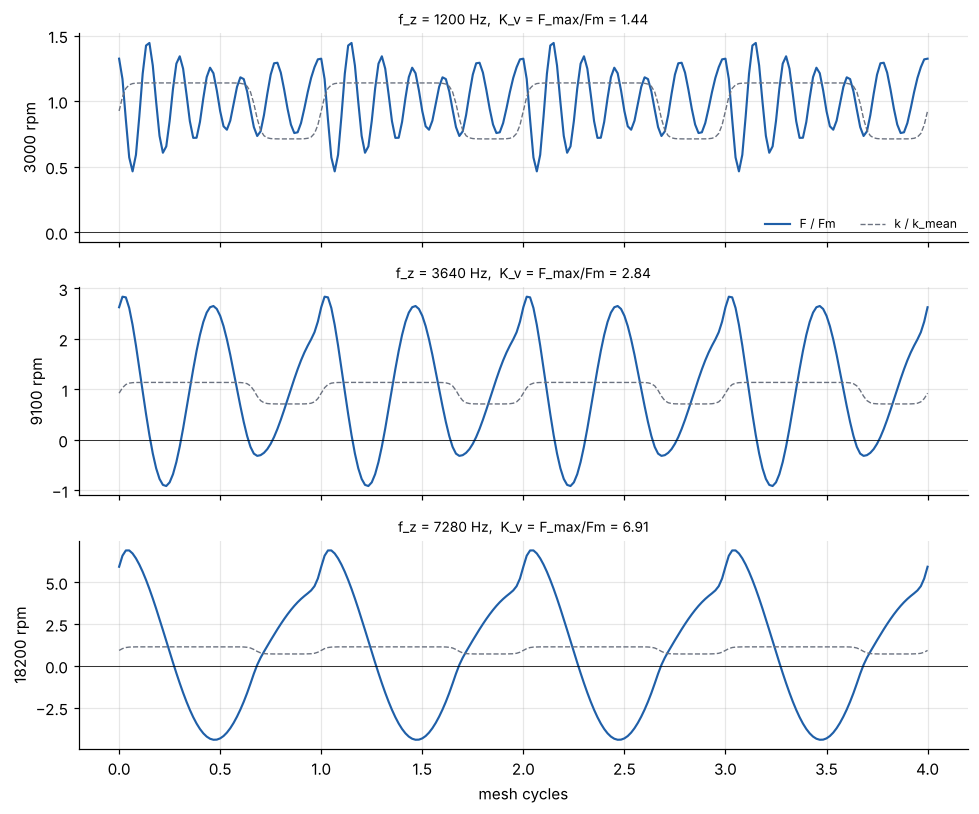

In [5]:
fig, ax = plt.subplots(3, 1, figsize=(9, 7.5), sharex=True)
for a, n in zip(ax, [3000, 9100, 18200]):
    r = gd.simulate_dte(gp, n, Fm, cycles=100, keep=4)
    ss = r["s"] - r["s"][0]
    a.plot(ss, r["F"] / Fm, label="F / Fm")
    a.plot(ss, gp.k_of_s(r["s"]) / gp.k_mesh, "--", color=gd.C["grey"], lw=0.9, label="k / k_mean")
    a.axhline(0, color="k", lw=0.5)
    a.set_ylabel(f"{n} rpm"); a.set_title(f"f_z = {gp.f_mesh(n):.0f} Hz,  K_v = F_max/Fm = {r['F'].max()/Fm:.2f}", fontsize=9)
ax[0].legend(ncol=2, fontsize=8, loc="lower right")
ax[-1].set_xlabel("mesh cycles")
plt.tight_layout()

* **3 000 rpm**: quasi-static. The force barely changes, but the *deflection* jumps with the
  stiffness (that's the STE). Small ringing follows each transition.
* **9 100 rpm**: the 2nd harmonic of $k$ excites the mesh mode, two wiggles per tooth.
* **18 200 rpm**: main resonance. The force swings far around $F_m$ and even goes **negative**,
  so the teeth would separate. The linear model is no longer valid; notebook 04 handles that.

## 5  Speed sweep: dynamic factor and dynamic transmission error

For each speed integrate until the transient has died out (80 mesh cycles), then evaluate
the last 20. Two classical outputs:

* **dynamic factor** $K_v = F_\max / F_m$ (ISO 6336's $K_v$ is the same idea, from a simplified model);
* **DTE peak-peak**: the vibration that drives the bearings and the housing.

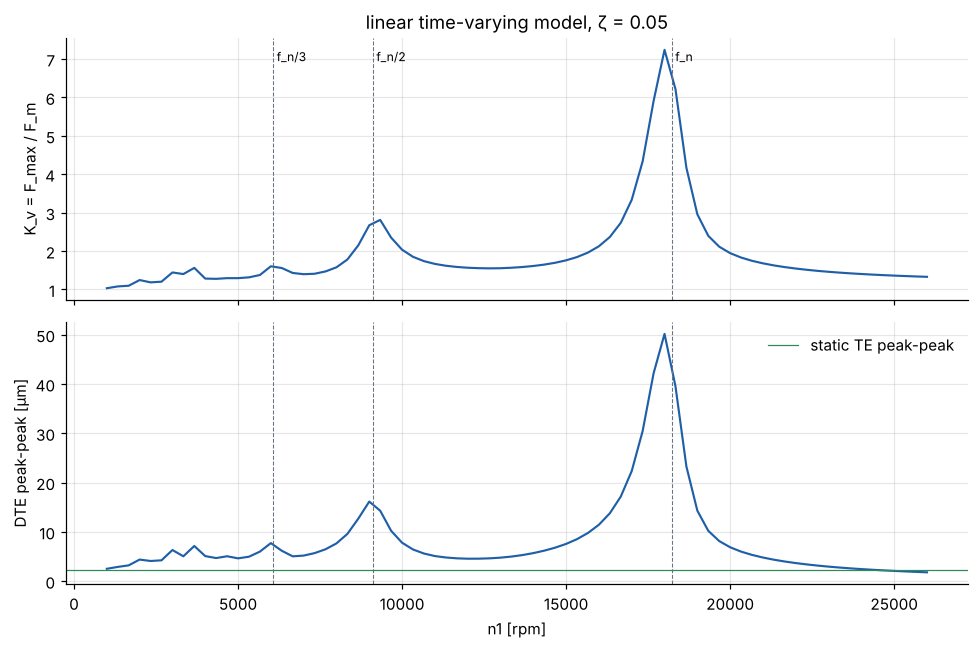

In [6]:
speeds = np.linspace(1000, 26000, 76)


def sweep(g, Fm=Fm, err=None, contact="linear"):
    Kv, dte = [], []
    for n in speeds:
        r = gd.simulate_dte(g, n, Fm, cycles=80, keep=20, err=err, contact=contact)
        Kv.append(r["F"].max() / Fm); dte.append(np.ptp(r["x"]))
    return np.array(Kv), np.array(dte)


Kv0, dte0 = sweep(gp)
fig, ax = plt.subplots(2, 1, figsize=(9, 6), sharex=True)
ax[0].plot(speeds, Kv0); ax[0].set_ylabel("K_v = F_max / F_m")
ax[1].plot(speeds, dte0 * 1e6); ax[1].set_ylabel("DTE peak-peak [µm]"); ax[1].set_xlabel("n1 [rpm]")
for j in [1, 2, 3]:
    nres = 60 * gp.f_n / (j * gp.z1)
    for a in ax:
        a.axvline(nres, color=gd.C["grey"], lw=0.7, ls="--")
    ax[0].text(nres, ax[0].get_ylim()[1] * 0.92, f" f_n/{j}" if j > 1 else " f_n", fontsize=8)
ax[1].axhline(np.ptp(ste) * 1e6, color=gd.C["green"], lw=0.8, label="static TE peak-peak")
ax[1].legend()
ax[0].set_title("linear time-varying model, ζ = 0.05")
plt.tight_layout()

## 6  Campbell diagram

Same information, drawn the way it's done for a drivetrain: excitation orders as rays,
the natural frequency as a horizontal line, resonances where they cross. For a gear, the
"orders" are $j\,z_1$ of the pinion speed.

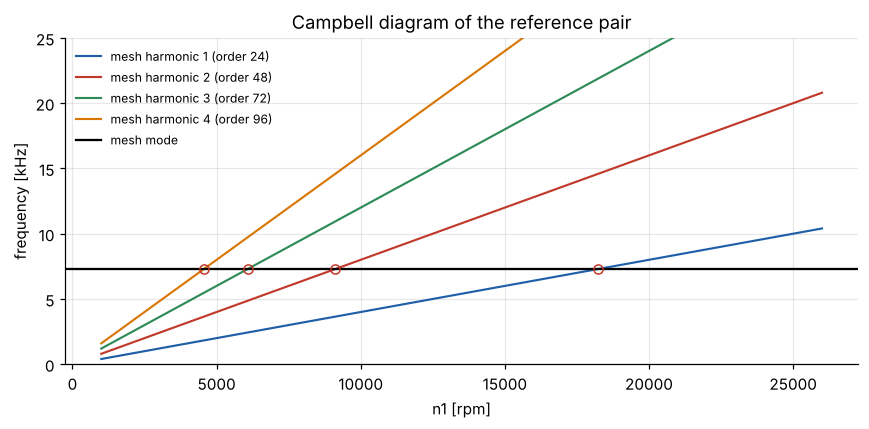

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
for j in [1, 2, 3, 4]:
    ax.plot(speeds, j * gp.f_mesh(speeds) / 1e3, label=f"mesh harmonic {j} (order {j*gp.z1})")
ax.axhline(gp.f_n / 1e3, color="k", lw=1.5, label="mesh mode")
for j in [1, 2, 3, 4]:
    n = 60 * gp.f_n / (j * gp.z1)
    ax.plot(n, gp.f_n / 1e3, "o", color=gd.C["red"], ms=6, mfc="none")
ax.set_xlabel("n1 [rpm]"); ax.set_ylabel("frequency [kHz]"); ax.set_ylim(0, 25)
ax.legend(fontsize=8); ax.set_title("Campbell diagram of the reference pair")
plt.tight_layout()

## 7  Parametric stability: Floquet multipliers

A periodic *coefficient* can do something that a periodic *force* cannot: make the zero
solution unstable. That is **parametric resonance** (a child pumping a swing). The test is
to integrate the homogeneous equation $m\ddot x + c\dot x + k(f_z t)x = 0$ over one mesh
period for two unit initial conditions. The resulting monodromy matrix has eigenvalues
(Floquet multipliers) $\mu$. If $|\mu| > 1$, the response grows without bound even at constant
load. Instability zones open near $f_z = 2f_n/j$. The damping has to beat them.

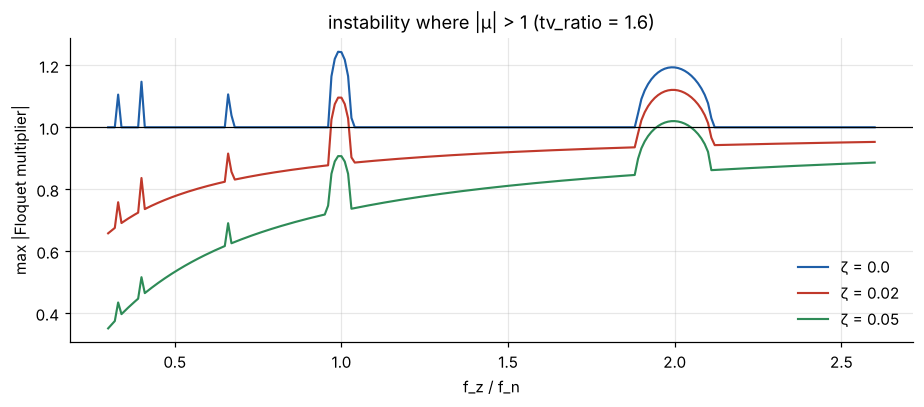

In [8]:
ratios = np.linspace(0.3, 2.6, 231)
fig, ax = plt.subplots(figsize=(8.5, 3.8))
for z in [0.0, 0.02, 0.05]:
    g = gp.with_(zeta=z)
    mu = [gd.floquet_multipliers(g, r * g.f_n * 60 / g.z1) for r in ratios]
    ax.plot(ratios, mu, label=f"ζ = {z}")
ax.axhline(1, color="k", lw=0.8)
ax.set_xlabel("f_z / f_n"); ax.set_ylabel("max |Floquet multiplier|")
ax.set_title(f"instability where |µ| > 1 (tv_ratio = {gp.tv_ratio})")
ax.legend()
plt.tight_layout()

Without damping the pair is unstable in bands at $f_z/f_n \approx 2$ and $1$, plus narrow
ones at $2/3, 2/5, 1/3, \dots$ With
$\zeta = 0.05$ the main zone ($f_z = 2f_n$, about 36 000 rpm here) is only just unstable. Our
reference pair never gets there, but light, fast gears (camtrain idlers, turbine gears) can.
Try `tv_ratio = 2` and $\zeta = 0.05$: the $f_z = f_n$ zone opens as well. In practice the
teeth then separate and the backlash nonlinearity (04) limits the amplitude.

## 8  Experiments

### 8a  Tip relief: soften the transitions

Profile modification (tip and root relief) lets a tooth pair take up load gradually instead
of with a step. In our model it maps to a wider `tv_smooth`. The mean stiffness stays the
same, but the higher harmonics collapse.

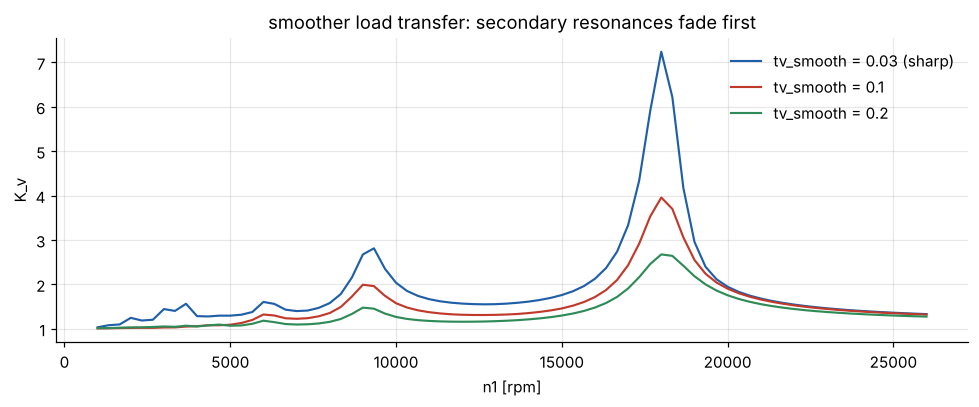

In [9]:
fig, ax = plt.subplots(figsize=(9, 3.8))
ax.plot(speeds, Kv0, label="tv_smooth = 0.03 (sharp)")
for sw in [0.10, 0.20]:
    Kv, _ = sweep(gp.with_(tv_smooth=sw))
    ax.plot(speeds, Kv, label=f"tv_smooth = {sw}")
ax.set_xlabel("n1 [rpm]"); ax.set_ylabel("K_v"); ax.legend()
ax.set_title("smoother load transfer: secondary resonances fade first")
plt.tight_layout()

### 8b  High contact ratio

Longer teeth (addendum 1.25 m, dedendum 1.45 m) push $\varepsilon_\alpha$ to about 2. Two pairs
are then always in contact, and in this simple model the stiffness becomes constant. Real
high-contact-ratio gears go 2 ↔ 3 pairs and keep a smaller ripple. Integer contact ratios
(and, for helical gears, integer overlap ratios) are the classic low-noise targets.

In [10]:
for ha, hf in [(1.0, 1.25), (1.15, 1.40), (1.25, 1.45)]:
    g = gp.with_(addendum=ha, dedendum=hf)
    kk = g.k_of_s(s)
    print(f"addendum {ha:.2f} m: eps_alpha = {g.eps_alpha:.3f}, k ripple peak-peak = "
          f"{np.ptp(kk)/g.k_mesh*100:5.1f} % of mean")

addendum 1.00 m: eps_alpha = 1.675, k ripple peak-peak =  42.7 % of mean
addendum 1.15 m: eps_alpha = 1.891, k ripple peak-peak =  38.1 % of mean
addendum 1.25 m: eps_alpha = 2.032, k ripple peak-peak =   0.0 % of mean


### 8c  Manufacturing error versus load

Pitch and profile errors add a geometric **displacement** excitation $e(s)$, in µm, to the
mesh: $F = k(s)\,(\delta - e(s)) + c\,\dot\delta$. Take a 1 µm sinusoidal profile error at
mesh frequency. Unlike the stiffness ripple, which scales with load, this excitation is
**fixed**, so it matters most at **light load**:

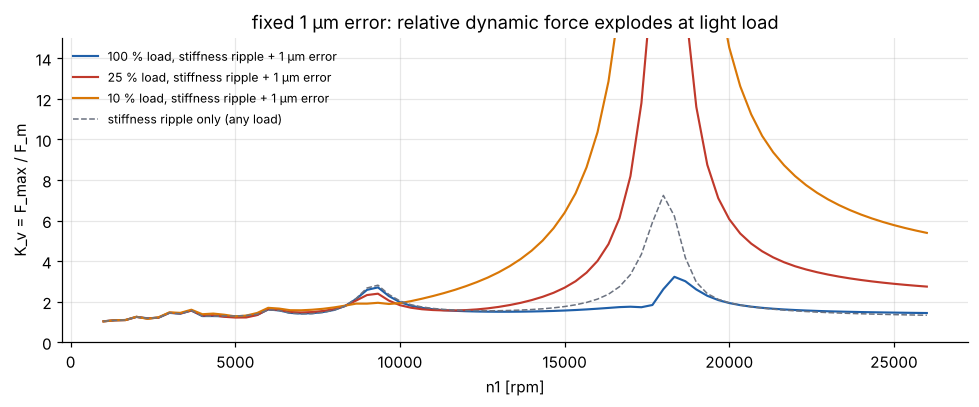

In [11]:
err = lambda s: 1.0e-6 * np.sin(2 * np.pi * s)
fig, ax = plt.subplots(figsize=(9, 3.8))
for frac, col in [(1.0, gd.C["blue"]), (0.25, gd.C["red"]), (0.10, gd.C["orange"])]:
    Kv_e, _ = sweep(gp, Fm=frac * Fm, err=err)
    ax.plot(speeds, Kv_e, color=col, label=f"{frac*100:.0f} % load, stiffness ripple + 1 µm error")
ax.plot(speeds, Kv0, "--", color=gd.C["grey"], lw=1, label="stiffness ripple only (any load)")
ax.set_xlabel("n1 [rpm]"); ax.set_ylabel("K_v = F_max / F_m"); ax.set_ylim(0, 15)
ax.set_title("fixed 1 µm error: relative dynamic force explodes at light load")
ax.legend(fontsize=8)
plt.tight_layout()

With only the stiffness ripple, one curve (dashed) fits every load, because the linear model
scales with $F_m$. The error excitation breaks that. At full load the error can even partly
*cancel* the stiffness excitation near resonance; that depends on their relative phase,
so check the sign of `err`. At 10 % load the dynamic force near
resonance is many times the static force, so the teeth must separate. **Light load plus
resonance means rattle and impacts.** That's the subject of notebook 04.

## 9  Take-aways

* The alternation of 1 and 2 tooth pairs makes $k$ periodic at the **mesh frequency**
  $z_1 n_1/60$. Under load this produces a transmission error, the gear's internal excitation.
* Equation of motion: $m_{eq}\ddot\delta + c\dot\delta + k(f_z t)\,\delta = F_m (+\,k\,e)$. Mesh
  harmonic $j$ is resonant at $n_1 = 60 f_n/(j z_1)$.
* A periodic stiffness can also **destabilize** (Floquet $|\mu|>1$, near $f_z \approx 2f_n/j$).
  Damping and the contact nonlinearity bound it.
* Levers against whine: tip relief (smoother transfer), contact ratio near an integer,
  accuracy (lower $e$), and keeping resonances out of the speed range.

## Exercises

1. Switch on `tv_ratio = 2.0` and rerun section 5. Where does the response blow up, and does
   the Floquet plot predict it?
2. Put the error at **twice** mesh frequency ($\sin 4\pi s$). Which resonance does it excite?
3. A pitch error on one tooth excites once per pinion revolution, i.e. order 1 with sidebands
   around the mesh orders. Build `err(s)` as a pulse every 24 mesh cycles and look at the
   spectrum of $F$ (`np.fft.rfft`).
4. Replace the rectangular $k(s)$ by your own single-pair stiffness curve (e.g. a parabola
   along the path) superposed for two pairs offset by one base pitch. Does $K_v$ change much?